# 03 — Customer Segmentation

> **Synthetic data disclosure.** RetailPulse 360 is fictional and all customers are synthetic. The segments below show the method; they do not describe a real customer base.

**Objective.** Group customers by purchase value, recency, discount use, refund behaviour, digital engagement and support usage, to support targeted retention, loyalty, win-back and marketing actions.

**Rules followed.**
- The churn target is **never** a clustering input. It is joined only afterwards, to describe the segments.
- Segment names come from the cluster profiles *after* clustering. There are no labels decided in advance.

## 1. Setup

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from retailpulse360 import data, features, plotting, segmentation
from retailpulse360.config import REPORTS_DIR

plotting.apply_style()
pd.set_option("display.float_format", "{:,.2f}".format)
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 160)
%matplotlib inline

In [2]:
tables = data.load_raw_tables()
frame = features.add_corrected_features(data.load_snapshot(), tables["orders"])
print(frame.shape)

(6000, 30)


## 2. Feature selection

| Feature | Dimension | Why |
|---|---|---|
| `days_since_last_purchase` | Recency (R) | true recency, not the snapshot sentinel |
| `frequency_12m` | Frequency (F) | purchase habit |
| `monetary_value_12m` | Monetary (M) | customer value |
| `gross_margin_pct_12m` | Profitability | value net of cost; separates high-margin from low-margin baskets |
| `avg_discount_pct_12m` | Discount use | price sensitivity |
| `refund_rate_12m` | Refund behaviour | post-purchase problems |
| `web_sessions_90d` | Engagement | recent digital intent |
| `support_tickets_12m` | Support load | service cost and friction |

`profit_12m`, `avg_order_value_12m` and `category_diversity_12m` are left out of the clustering because they are highly correlated with monetary value and frequency (r > 0.75; see Notebook 02). Including them would give the value dimension too much weight. They are still used to **profile** the segments.

In [3]:
selected = frame[segmentation.SEGMENT_FEATURES]
print("Missing values per feature:", int(selected.isna().sum().sum()))
selected.describe().T

Missing values per feature: 0


,count,mean,std,min,25%,50%,75%,max
days_since_last_purchase,"6,000.00",120.98,132.95,0.00,29.00,77.00,164.00,"1,206.00"
frequency_12m,"6,000.00",2.70,2.02,0.00,1.00,2.00,4.00,14.00
monetary_value_12m,"6,000.00",345.30,306.20,0.00,112.55,275.08,497.97,"2,205.77"
gross_margin_pct_12m,"6,000.00",0.38,0.15,0.00,0.36,0.41,0.46,0.80
avg_discount_pct_12m,"6,000.00",2.58,4.06,0.00,0.00,0.00,4.38,25.00
refund_rate_12m,"6,000.00",0.04,0.13,0.00,0.00,0.00,0.00,1.00
web_sessions_90d,"6,000.00",2.13,1.59,0.00,1.00,2.00,3.00,13.00
support_tickets_12m,"6,000.00",0.51,0.76,0.00,0.00,0.00,1.00,5.00


## 3. Missing values, skew and transformation

There are no missing values. Customers without purchases carry 0 for frequency, value, margin and discount. That is a real state ("no purchases"), not missing data.

K-Means uses Euclidean distance, so heavy right skew would let a few extreme customers dominate. Skewed counts and amounts are therefore `log1p`-transformed, and every feature is then standardised (mean 0, SD 1) so that no unit, such as dollars against counts, dominates.

In [4]:
segmentation.skew_table(frame)

,skew_raw,skew_after_transform,log_transformed
days_since_last_purchase,2.22,-0.70,True
frequency_12m,1.16,-0.35,True
monetary_value_12m,1.37,-1.76,True
gross_margin_pct_12m,-1.54,-1.54,False
avg_discount_pct_12m,2.16,0.69,True
refund_rate_12m,4.65,4.65,False
web_sessions_90d,0.93,-0.36,True
support_tickets_12m,1.63,0.89,True


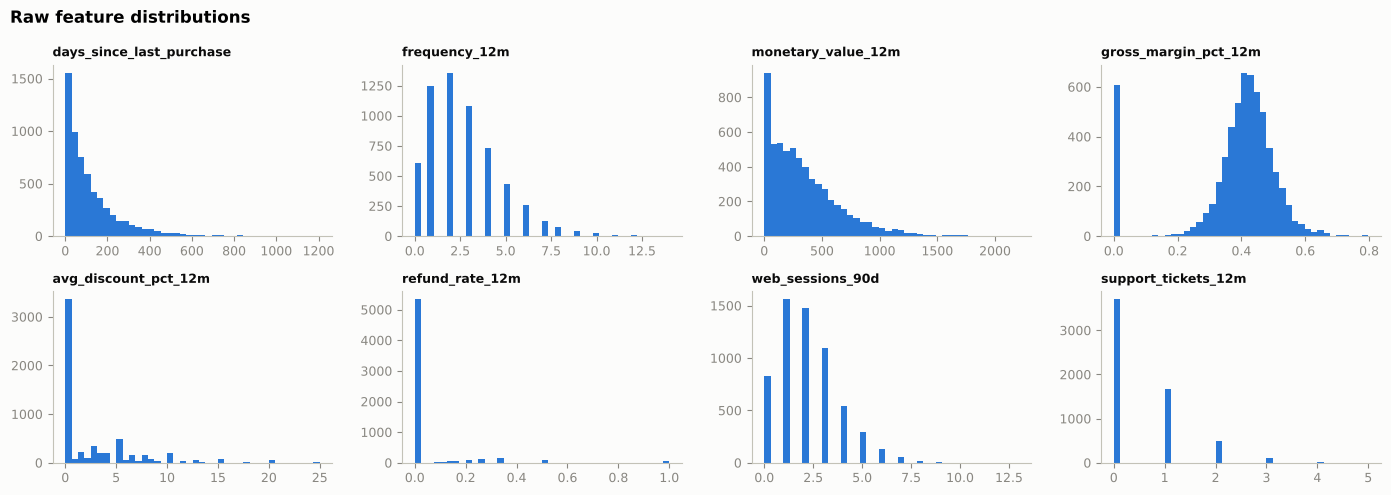

In [5]:
logged = segmentation._log_selected(selected)
fig, axes = plt.subplots(2, 4, figsize=(14, 5))
for ax, column in zip(axes.flat, segmentation.SEGMENT_FEATURES):
    ax.hist(selected[column], bins=40, color=plotting.PRIMARY_COLOR)
    ax.set_title(column, fontsize=9)
    ax.grid(False)
fig.suptitle("Raw feature distributions", x=0.01, ha="left", fontweight="bold")
fig.tight_layout()
plt.show()

`refund_rate_12m` stays skewed because most customers have zero refunds. A log transform does not help a variable that is mostly zero. It is kept on its original scale because a high refund rate is exactly the kind of behaviour segmentation should surface.

In [6]:
matrix = segmentation.segment_matrix(frame)
print("Scaled matrix:", matrix.shape, "| means ≈ 0:", np.allclose(matrix.mean(axis=0), 0), "| SDs ≈ 1:", np.allclose(matrix.std(axis=0), 1))

Scaled matrix: (6000, 8) | means ≈ 0: True | SDs ≈ 1: True


## 4. Choosing the number of clusters

**Method.** Fit K-Means for k = 2…8 (20 initialisations each, fixed seed). Compare inertia (elbow) and silhouette, and check that no cluster is too small to act on.

In [7]:
k_eval = segmentation.evaluate_k(matrix)
k_eval

,k,inertia,silhouette,smallest_cluster_pct
0,2,"34,511.79",0.47,10.13
1,3,"29,112.32",0.22,10.10
2,4,"25,895.50",0.23,5.07
3,5,"23,094.72",0.22,4.88
4,6,"21,127.65",0.22,2.68
5,7,"19,572.50",0.22,0.78
6,8,"18,034.08",0.24,0.78


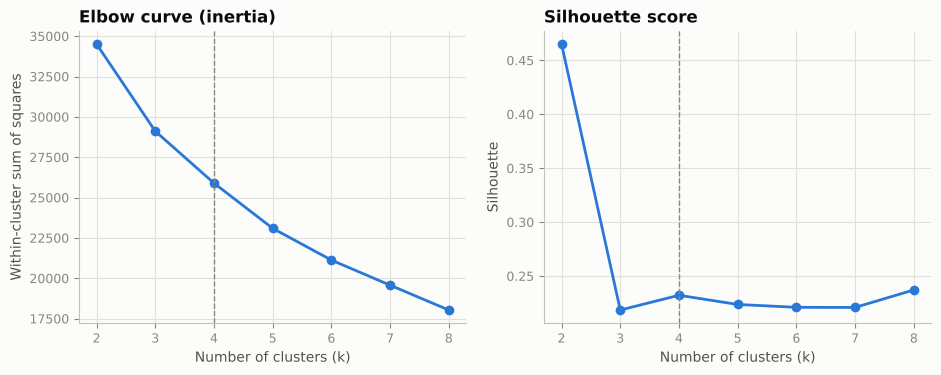

**Chosen k = 4** (silhouette 0.232).

In [8]:
k = segmentation.choose_k(k_eval)
fig = plotting.k_selection_plot(k_eval, k)
plt.show()
display(Markdown(f"**Chosen k = {k}** (silhouette {k_eval.set_index('k').loc[k, 'silhouette']:.3f})."))

**Justification.**
- **k = 2 has the highest silhouette, but it is not useful.** It only separates customers with no recent purchase from everyone else, which is already known without clustering.
- The **selection rule** (`segmentation.choose_k`) picks the highest silhouette among k ≥ 3 where every cluster holds at least 5% of customers. Smaller groups are too small to justify a dedicated campaign.
- The elbow curve has no sharp bend, and silhouettes for k ≥ 3 are about 0.22–0.24. That is **weak to moderate separation**: customers form a continuum, and the segments are useful summaries rather than sharply distinct groups. This is stated openly instead of being hidden.

## 5. Fit and check stability

In [9]:
model = segmentation.fit_kmeans(matrix, k)
labels = model.labels_
stability = segmentation.stability(matrix, k)
pd.Series(stability).to_frame("adjusted Rand index")

,adjusted Rand index
seed_ari_min,1.00
seed_ari_mean,1.00
bootstrap_ari_mean,0.85
bootstrap_ari_min,0.51


- **Across random seeds** the solution is almost identical (ARI ≈ 1.0), so it is reproducible.
- **Across bootstrap resamples** the mean ARI is about 0.85, with one weaker resample. The main segments are reasonably stable, but the boundaries between neighbouring groups move. This is consistent with the moderate silhouette.

## 6. Profile the clusters

In [10]:
profile = segmentation.profile_segments(frame, labels)
profile.T

cluster,0,1,2,3
customers,"2,545.00","2,592.00",559.00,304.00
share_pct,42.42,43.20,9.32,5.07
days_since_last_purchase,78.49,106.34,356.50,168.34
frequency_12m,3.82,2.33,0.00,1.46
monetary_value_12m,477.95,307.05,0.00,195.78
profit_12m,194.06,132.94,0.00,82.33
avg_order_value_12m,123.97,132.83,0.00,109.00
gross_margin_pct_12m,0.41,0.44,0.00,0.36
avg_discount_pct_12m,5.83,0.02,0.00,1.96
refund_rate_12m,0.02,0.01,0.00,0.50


In [11]:
columns = ["days_since_last_purchase", "frequency_12m", "monetary_value_12m", "gross_margin_pct_12m", "avg_discount_pct_12m", "refund_rate_12m", "web_sessions_90d", "support_tickets_12m"]
weights = profile["customers"]
overall = profile[columns].mul(weights, axis=0).sum() / weights.sum()
indexed = 100 * profile[columns] / overall
indexed.round(0)

,days_since_last_purchase,frequency_12m,monetary_value_12m,gross_margin_pct_12m,avg_discount_pct_12m,refund_rate_12m,web_sessions_90d,support_tickets_12m
cluster,,,,,,,,
0,65.00,142.00,138.00,107.00,226.00,48.00,99.00,101.00
1,88.00,86.00,89.00,116.00,1.00,26.00,101.00,100.00
2,295.00,0.00,0.00,0.00,0.00,0.00,103.00,95.00
3,139.00,54.00,57.00,95.00,76.00,"1,351.00",96.00,108.00


**Reading the index (100 = customer average).**
- One cluster has frequency and value about 40% above average and the **highest discount use** (about 2× average). It also has a below-average refund rate and the most recent purchases.
- One cluster buys at **almost exactly full price** (discount index ≈ 1), with somewhat below-average frequency and value and the highest margin.
- One cluster has **no purchase in the last 12 months** (frequency, value and margin = 0, recency about 3× average). About half of it has never purchased.
- One small cluster has a **refund rate about 13× average** (around half of its orders are refunded) and lower value.
- Web sessions and support tickets are close to average in every cluster, so they do **not** separate customers in this data.

### Naming rules (applied to the profiles, in order)

1. Average 12-month frequency < 0.5 → **Lapsed / No Recent Purchase**
2. Refund rate > 2× average and > 10% → **Refund-Prone Buyers**
3. Monetary value > 1.5× average → **High-Value Loyalists**
4. Discount > 1.5× average → **Promotion-Driven (Frequent) Buyers**
5. Discount < 0.25× average → **Full-Price Regulars**
6. Support tickets > 2× average → **Support-Heavy Customers**
7. Recency worse than average → **Cooling Occasional Buyers**, otherwise **Steady Core Buyers**

In [12]:
names = segmentation.name_segments(profile)
profile.insert(0, "segment", profile.index.map(names))
frame["segment"] = pd.Series(labels, index=frame.index).map(names)
profile[["segment", "customers", "share_pct", "days_since_last_purchase", "frequency_12m", "monetary_value_12m", "avg_discount_pct_12m", "refund_rate_12m", "profit_share_pct"]]

,segment,customers,share_pct,days_since_last_purchase,frequency_12m,monetary_value_12m,avg_discount_pct_12m,refund_rate_12m,profit_share_pct
cluster,,,,,,,,,
0,Promotion-Driven Frequent Buyers,2545,42.42,78.49,3.82,477.95,5.83,0.02,57.20
1,Full-Price Regulars,2592,43.20,106.34,2.33,307.05,0.02,0.01,39.91
2,Lapsed / No Recent Purchase,559,9.32,356.50,0.00,0.00,0.00,0.00,0.00
3,Refund-Prone Buyers,304,5.07,168.34,1.46,195.78,1.96,0.50,2.90


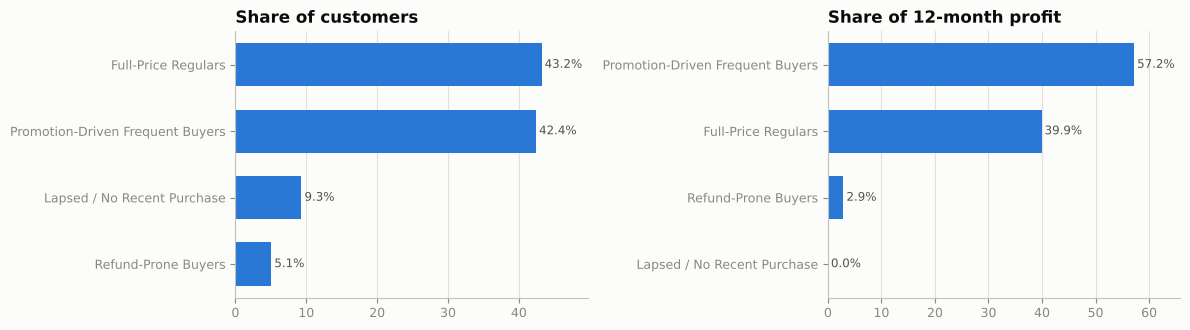

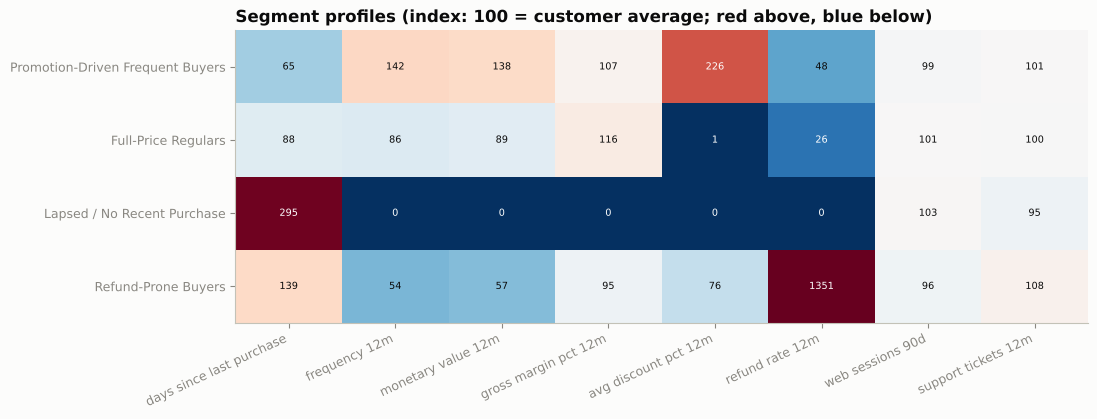

In [13]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 3.4))
plotting.barh_chart(profile, "segment", "share_pct", "Share of customers", fmt="{:.1f}%", ax=ax1)
plotting.barh_chart(profile, "segment", "profit_share_pct", "Share of 12-month profit", fmt="{:.1f}%", ax=ax2)
fig.tight_layout()
plt.show()

indexed.index = profile["segment"]
fig, ax = plt.subplots(figsize=(11, 3.8))
plotting.indexed_profile_heatmap(indexed, "Segment profiles (index: 100 = customer average; red above, blue below)", ax=ax)
ax.set_xticks(range(len(columns)), [c.replace("_", " ") for c in columns], rotation=25, ha="right")
plt.show()

## 7. Segments and churn (descriptive only — the target was not used to cluster)

In [14]:
churn_by_segment = frame.groupby("segment").agg(customers=("customer_id", "size"), churn_rate_pct=(features.TARGET, "mean"), loyalty_platinum_gold_pct=("loyalty_tier", lambda s: s.isin(["Gold", "Platinum"]).mean()))
churn_by_segment[["churn_rate_pct", "loyalty_platinum_gold_pct"]] *= 100
churn_by_segment.sort_values("churn_rate_pct")

,customers,churn_rate_pct,loyalty_platinum_gold_pct
segment,,,
Promotion-Driven Frequent Buyers,2545,16.74,22.36
Full-Price Regulars,2592,26.04,17.82
Refund-Prone Buyers,304,47.04,20.72
Lapsed / No Recent Purchase,559,63.51,10.02


In [15]:
pd.crosstab(frame["segment"], frame["loyalty_tier"], normalize="index").mul(100).round(1)[["Bronze", "Silver", "Gold", "Platinum"]]

loyalty_tier,Bronze,Silver,Gold,Platinum
segment,,,,
Full-Price Regulars,53.90,28.30,14.10,3.70
Lapsed / No Recent Purchase,64.60,25.40,9.10,0.90
Promotion-Driven Frequent Buyers,47.70,30.00,17.10,5.30
Refund-Prone Buyers,48.00,31.20,17.80,3.00


Churn differs sharply between segments, although churn was never a clustering input. This shows the behavioural segments capture risk. Loyalty-tier mix is similar across the three buying segments (17–22% Gold or Platinum), while lapsed customers hold fewer high tiers. The segments therefore add behavioural information that tier alone does not capture.

## 8. Recommended actions per segment

In [16]:
playbook = {
    "Promotion-Driven Frequent Buyers": ("Protect and grow the most valuable group without training them to wait for discounts.",
        "Test loyalty rewards or free shipping in place of percentage discounts on a holdout group; cross-sell new categories.",
        "Margin %, order frequency, churn rate (test vs control)"),
    "Full-Price Regulars": ("Healthy margin, but buying less often than the promotion group.",
        "Use frequency nudges such as replenishment reminders, new-arrival emails and loyalty-tier progress, not discounts.",
        "Orders per customer, days between orders, margin %"),
    "Lapsed / No Recent Purchase": ("No purchase in 12 months and the highest churn; about half never bought.",
        "Run a low-cost win-back sequence for previous buyers and an onboarding or first-purchase offer for never-buyers; stop paid retargeting that does not convert.",
        "Reactivation rate, cost per reactivated customer"),
    "Refund-Prone Buyers": ("About half of orders refunded; small group with high churn and refund losses.",
        "Find root causes by product (sizing, descriptions, quality), and check for return-policy abuse before offering incentives.",
        "Refund rate, refund loss, CSAT after refund"),
}
rows = []
for segment in profile.sort_values("profit_share_pct", ascending=False)["segment"]:
    goal, action, kpi = playbook.get(segment, ("Review profile", "Define an action after reviewing the profile", "Segment KPIs"))
    rows.append({"segment": segment, "customers": int(profile.set_index("segment").loc[segment, "customers"]), "situation": goal, "recommended action (to test)": action, "monitor": kpi})
pd.set_option("display.max_colwidth", 120)
pd.DataFrame(rows)

,segment,customers,situation,recommended action (to test),monitor
0,Promotion-Driven Frequent Buyers,2545,Protect and grow the most valuable group without training them to wait for discounts.,Test loyalty rewards or free shipping in place of percentage discounts on a holdout group; cross-sell new categories.,"Margin %, order frequency, churn rate (test vs control)"
1,Full-Price Regulars,2592,"Healthy margin, but buying less often than the promotion group.","Use frequency nudges such as replenishment reminders, new-arrival emails and loyalty-tier progress, not discounts.","Orders per customer, days between orders, margin %"
2,Refund-Prone Buyers,304,About half of orders refunded; small group with high churn and refund losses.,"Find root causes by product (sizing, descriptions, quality), and check for return-policy abuse before offering incen...","Refund rate, refund loss, CSAT after refund"
3,Lapsed / No Recent Purchase,559,No purchase in 12 months and the highest churn; about half never bought.,Run a low-cost win-back sequence for previous buyers and an onboarding or first-purchase offer for never-buyers; sto...,"Reactivation rate, cost per reactivated customer"


Every action is a **hypothesis to test with a control group**. The data shows who the customers are, not how they will respond to an intervention.

## 9. Consistency with saved outputs

In [17]:
saved = json.loads((REPORTS_DIR / "model_metrics.json").read_text())["segmentation"]
assert saved["k"] == k
assert sorted(saved["segment_names"].values()) == sorted(names.values())
print("Notebook segmentation matches reports/model_metrics.json (written by scripts/run_pipeline.py).")

Notebook segmentation matches reports/model_metrics.json (written by scripts/run_pipeline.py).


## 10. Limitations

- **Weak to moderate cluster structure** (silhouette ≈ 0.23). The segments are practical summaries of a continuum, not natural groups.
- **K-Means assumptions.** It favours round clusters of similar size and is sensitive to scaling choices; the log transform and standardisation shape the result.
- **Synthetic data.** Engagement and support features barely differ across customers, unlike in most real businesses, so they contribute little here.
- **Single snapshot.** Segment membership changes over time. In production, segments would be refreshed monthly and migration between segments tracked.
- **No response data.** The playbook actions are untested hypotheses.